In [1]:
import os
os.chdir("..")

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from optimizer import grid_search, strategy_compare

In [3]:
STRATEGIES = {
    "BuyHold": {"classic_dca": True},
    "Default": {},
    "NoConfirm": {"manual_sell_fraction": 0.5, "minimum_profit": 2.0},
    "Exponential": {"cooldown_long": 90},
}

In [4]:
df_prices = pd.read_csv("data/test_crypto.csv", index_col=0, parse_dates=True)
df_prices

,BTC,ETH,SOL,XRP,DOGE,ADA,DOT,LINK,XLM,XMR
Date,,,,,,,,,,
2014-09-17,457.334015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-18,424.440002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-19,394.795990,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-20,408.903992,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-21,398.821014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
2026-10-20,82941.000000,2446.730713,106.422340,1.334452,0.081809,0.223782,1.149771,12.320927,0.181960,600.929504
2026-10-21,84011.968750,2470.766113,106.793655,1.363619,0.081867,0.224979,1.141323,12.484719,0.183488,622.434082
2026-10-22,81311.890625,2386.189209,103.542320,1.307656,0.078676,0.212025,1.111869,11.943166,0.175209,600.638428


# COMPARE

In [5]:
history_compare = strategy_compare(
    prices=df_prices,
    strategies=STRATEGIES,
    n_boot=100,
    sample_size=10,
    sequence_length=365 * 4,
)

100%|██████████| 4/4 [03:29<00:00, 52.28s/it]


In [6]:
history_compare

,strategy,Target,Cash_spent,Realized_cash,Portfolio,Invested,Total_value,Bull_history,Avg_price,Num_take_profits,MDD,MA200_survival_days,RoAC,iteration
0,BuyHold,ETH,2059,0,7172,2059,7172,96,672.110061,0,-9322,205.333333,314,1
1,BuyHold,LINK,2059,0,3227,2059,3227,47,10.886488,0,-3143,102.333333,4,1
2,BuyHold,DOT,2059,0,702,2059,702,16,5.422775,0,-1895,103.750000,-23,1
3,BuyHold,ADA,2069,0,3695,2069,3695,92,0.156748,0,-29074,331.000000,581,1
4,BuyHold,XMR,2059,0,2071,2059,2071,49,161.523652,0,-836,17.000000,14,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3995,Exponential,SOL,2168,1972,1153,1409,3125,85,79.353642,6,-2450,0.000000,233,100
3996,Exponential,XRP,2069,2317,1164,1102,3482,80,1.216467,4,-1129,65.500000,175,100
3997,Exponential,ETH,2059,3233,1522,1076,4755,80,1255.678680,6,-1943,222.500000,377,100
3998,Exponential,XMR,2069,2148,2149,989,4298,51,186.900428,3,-824,65.800000,26,100


In [11]:
compare_res = history_compare.groupby("strategy").agg(
    RoAC=("RoAC", "mean"),
    MDD=("MDD", "mean"),
    Portfolio=("Portfolio", "mean"),
    Realized_cash=("Realized_cash", "mean"),
    Cash_spent=("Cash_spent", "mean"),
    Total_value_mean=("Total_value", "mean"),
    Total_value_median=("Total_value", "median"),
    Total_value_low=("Total_value", lambda s: np.percentile(s, 25)),
    Total_value_high=("Total_value", lambda s: np.percentile(s, 75)),
)

compare_res.sort_values("RoAC", ascending=False).style.background_gradient(cmap="RdYlGn", axis=0).format("{:.2f}")

,RoAC,MDD,Portfolio,Realized_cash,Cash_spent,Total_value_mean,Total_value_median,Total_value_low,Total_value_high
strategy,,,,,,,,,
NoConfirm,467.64,-952.92,866.03,3703.39,2175.50,4569.89,3993.00,3308.00,4816.25
Default,354.43,-682.71,812.02,3303.96,2184.76,4116.48,3706.00,3101.50,4537.25
Exponential,314.34,-2775.31,1480.06,3467.63,2163.36,4948.17,3743.50,3008.75,5182.25
BuyHold,258.09,-22004.17,7533.58,0.00,2064.78,7533.58,3578.00,2245.00,7322.75


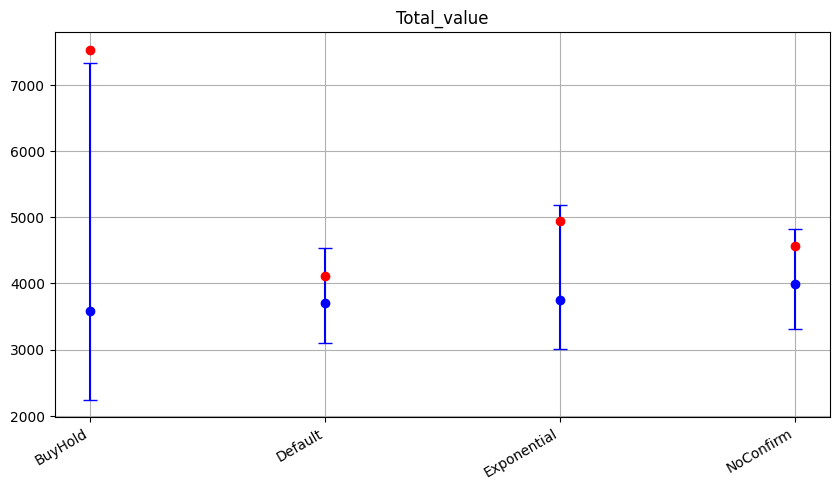

In [13]:
metric = "Total_value"

plt.figure(figsize=(10, 5))

median = compare_res[f"{metric}_median"]
mean = compare_res[f"{metric}_mean"]
low = compare_res[f"{metric}_low"]
high = compare_res[f"{metric}_high"]

plt.errorbar(
    median.index,
    median.values,
    yerr=[median - low, high - median],
    fmt="o",
    capsize=5,
    label="median",
    color="blue",
)
plt.errorbar(
    mean.index,
    mean.values,
    fmt="o",
    capsize=5,
    label="mean",
    color="red",
)
plt.title(metric)
plt.xticks(rotation=30, ha="right")
plt.grid()
plt.show()